# 03 — Target Analysis

Base rate of the top-quintile label by year and by month (seasonality?),
persistence of winners (does last week's top quintile stay top?), sector
concentration of the picks, and the return distribution of top-quintile
stocks vs the rest.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import data as data_mod
from src import features as feat_mod
from src import models as models_mod
from src import simulate as sim_mod
from src.target import make_target, time_split

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (10, 5)

# Same parameters as the fuller main.py run (50 tickers, 5 years).
# Downloads are cached under data/ (7-day freshness), so re-running is fast.
tickers = data_mod.get_universe(n=50)
prices = data_mod.download_prices(tickers, years=5)
macro = data_mod.download_macro(years=5)
french = data_mod.download_french_weekly()
spy = data_mod.download_benchmark(years=5)

feat = feat_mod.build_features(prices, macro=macro, french=french)
panel = make_target(feat)
panel['year'] = pd.to_datetime(panel['date']).dt.year
panel['month'] = pd.to_datetime(panel['date']).dt.month
print(f"Panel: {len(panel):,} rows, base rate {panel['target'].mean():.3f}")

Universe: 503 tickers from Wikipedia S&P 500 list.
Prices: using cache /home/hatch/workspace/stock-markets-analytics-project/data/prices_weekly.parquet
Macro: using cache /home/hatch/workspace/stock-markets-analytics-project/data/macro_weekly.parquet
French factors: using cache /home/hatch/workspace/stock-markets-analytics-project/data/french_weekly.parquet
Benchmark: using cache /home/hatch/workspace/stock-markets-analytics-project/data/spy_weekly.parquet


Features: 10,550 rows after dropping 2,550 incomplete rows; 50 tickers, 211 weeks.
Target: 10,500 rows, positive rate 0.200 (expected ~0.20).
Panel: 10,500 rows, base rate 0.200


## Base rate by year and by month

      top_quintile_rate     n
year                         
2022                0.2   350
2023                0.2  2600
2024                0.2  2650
2025                0.2  2600
2026                0.2  2300


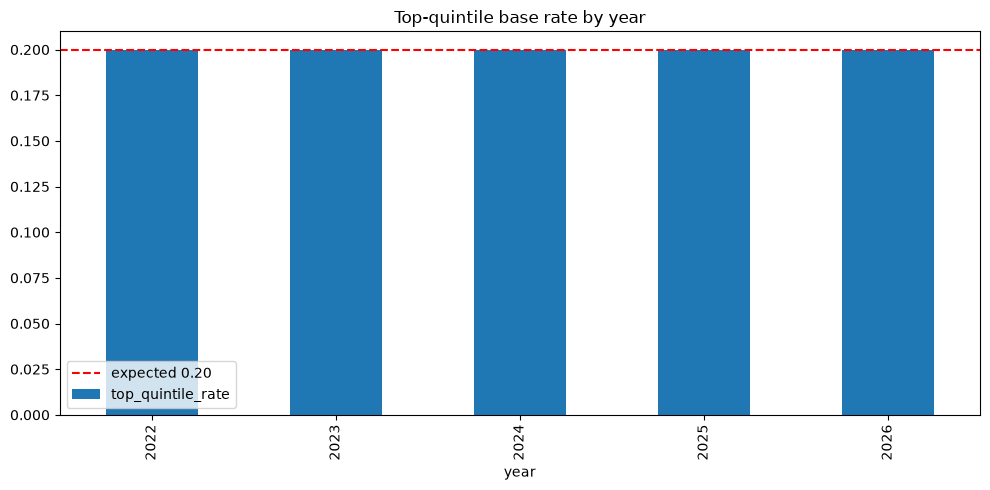

       top_quintile_rate    n
month                        
1                    0.2  900
2                    0.2  800
3                    0.2  900
4                    0.2  850
5                    0.2  850
6                    0.2  900
7                    0.2  900
8                    0.2  850
9                    0.2  900
10                   0.2  850
11                   0.2  900
12                   0.2  900


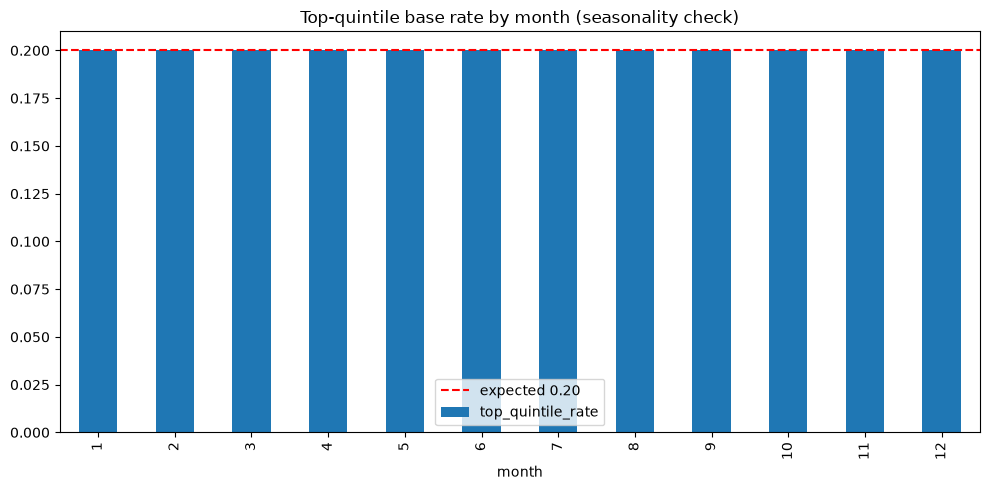

In [2]:
by_year = panel.groupby('year')['target'].agg(['mean', 'size']).round(3)
by_year.columns = ['top_quintile_rate', 'n']
print(by_year)
fig, ax = plt.subplots()
by_year['top_quintile_rate'].plot.bar(ax=ax)
ax.axhline(0.20, color='red', linestyle='--', label='expected 0.20')
ax.set_title('Top-quintile base rate by year')
ax.legend()
plt.tight_layout()
plt.show()
by_month = panel.groupby('month')['target'].agg(['mean', 'size']).round(3)
by_month.columns = ['top_quintile_rate', 'n']
print(by_month)
fig, ax = plt.subplots()
by_month['top_quintile_rate'].plot.bar(ax=ax)
ax.axhline(0.20, color='red', linestyle='--', label='expected 0.20')
ax.set_title('Top-quintile base rate by month (seasonality check)')
ax.set_xlabel('month')
ax.legend()
plt.tight_layout()
plt.show()

## Persistence of winners

If last week's winners tend to stay winners, momentum is real in this
universe and the target is partly predictable from last week's outcome
alone. Compare against the 20% base rate.

In [3]:
p = panel.sort_values(['ticker', 'date']).copy()
p['prev_target'] = p.groupby('ticker')['target'].shift(1)
p = p.dropna(subset=['prev_target'])
stay = p[p['prev_target'] == 1]['target'].mean()
leave = p[p['prev_target'] == 0]['target'].mean()
print(f"P(top this week | top last week)     = {stay:.3f}")
print(f"P(top this week | not top last week) = {leave:.3f}")
print(f"Base rate                            = 0.200")
p['prev2_target'] = p.groupby('ticker')['target'].shift(2)
p2 = p.dropna(subset=['prev2_target'])
stay2 = p2[(p2['prev_target'] == 1) & (p2['prev2_target'] == 1)]['target'].mean()
print(f"P(top this week | top last 2 weeks)  = {stay2:.3f}")

P(top this week | top last week)     = 0.233
P(top this week | not top last week) = 0.192
Base rate                            = 0.200
P(top this week | top last 2 weeks)  = 0.267


## Sector concentration of the picks

Sectors come from the Wikipedia S&P 500 table (GICS Sector column).
If the top-quintile picks concentrate in one or two sectors, the
strategy is implicitly making a sector bet -- worth knowing before
trading it.

In [4]:
import io
import requests

headers = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) "
                         "AppleWebKit/537.36 (KHTML, like Gecko) "
                         "Chrome/120.0 Safari/537.36"}
resp = requests.get(data_mod.WIKI_SP500_URL, headers=headers, timeout=30)
wiki = pd.read_html(io.StringIO(resp.text))[0]
wiki['Symbol'] = wiki['Symbol'].str.replace('.', '-', regex=False)
sector = dict(zip(wiki['Symbol'], wiki['GICS Sector']))
panel['sector'] = panel['ticker'].map(sector)
picks = panel[panel['target'] == 1]
uni_share = panel['sector'].value_counts(normalize=True)
pick_share = picks['sector'].value_counts(normalize=True)
cmp = pd.DataFrame({'universe_share': uni_share,
                    'pick_share': pick_share}).fillna(0).round(3)
cmp['lift'] = (cmp['pick_share'] / cmp['universe_share']).round(2)
print(cmp.sort_values('pick_share', ascending=False))

                        universe_share  pick_share  lift
sector                                                  
Information Technology            0.18       0.226  1.26
Financials                        0.22       0.193  0.88
Communication Services            0.08       0.113  1.41
Health Care                       0.10       0.102  1.02
Utilities                         0.12       0.084  0.70
Consumer Discretionary            0.06       0.065  1.08
Materials                         0.06       0.058  0.97
Industrials                       0.08       0.052  0.65
Consumer Staples                  0.04       0.039  0.98
Real Estate                       0.04       0.034  0.85
Energy                            0.02       0.033  1.65


## Return distribution: top quintile vs the rest

Top quintile next-week return: mean 5.58%, median 4.75%
Rest next-week return:         mean -0.98%, median -0.42%


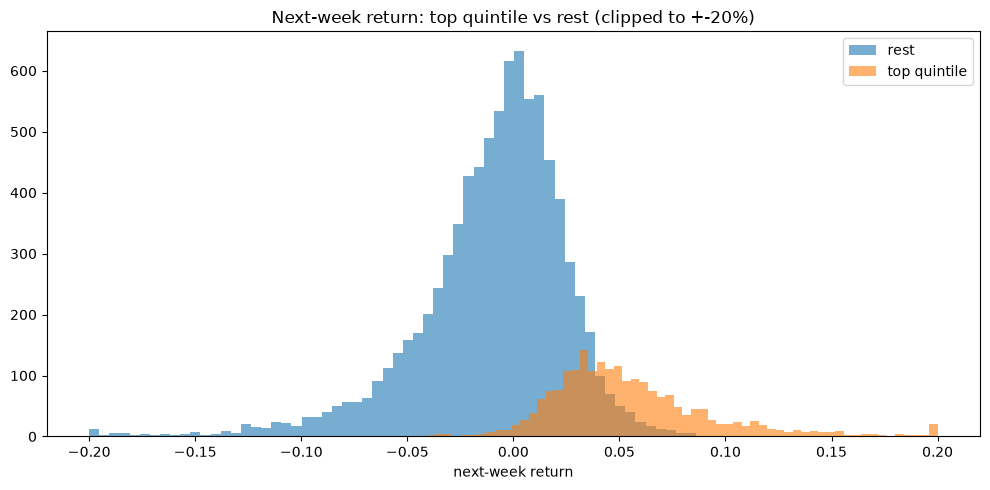

In [5]:
top = panel[panel['target'] == 1]['next_ret']
rest = panel[panel['target'] == 0]['next_ret']
print(f"Top quintile next-week return: mean {top.mean():.2%}, "
      f"median {top.median():.2%}")
print(f"Rest next-week return:         mean {rest.mean():.2%}, "
      f"median {rest.median():.2%}")
fig, ax = plt.subplots()
ax.hist(rest.clip(-0.2, 0.2), bins=60, alpha=0.6, label='rest')
ax.hist(top.clip(-0.2, 0.2), bins=60, alpha=0.6, label='top quintile')
ax.set_title('Next-week return: top quintile vs rest (clipped to +-20%)')
ax.set_xlabel('next-week return')
ax.legend()
plt.tight_layout()
plt.show()